# Лабораторная работа 4 (В26)
## Введение
**Название:** бинарная классификация

**Цель:** познакомиться с применением модели машинного обучения для решения задачи классификации (метод логистической регрессии)

**Описание показателей:**
- age - возраст
- job - тип работы
- marital - семейное положение
- education - образование
- default - просрочен ли кредит
- balance - среднегодовой баланс в евро
- housing - есть ли ссуда на жильё
- loan - есть ли ссуда на личные нужды
- contact - тип связи с контактом
- day - последний день контакта в месяце
- month - месяц последнего контакта в году
- duration - продолжительность последнего контакта в секундах
- campaign - количество контактов, осуществлённых в ходе этой компании и для данного клиента
- pdays - количество дней с момента последнего контакта с клиентом в рамках предыдущей компании
- previous - количество контактов, осуществлённых до этой компании и для данного клиента
- poutcome - результат предыдущей маркетинговой компании

**Результат:** y - клиент подпишется на срочный депозит? (двоичный код: "да", "нет")
## 1. Подготовительный этап
## 1.1 Импортируем библиотеки и загружаем данные

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# используем указание разделителя delimiter
df = pd.read_csv('bank.csv', delimiter = ';')
# скопируем датафрейм на будущее (глава 6)
df_copy = df
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


### 1.2 Извлекаем последнюю строку датафрейма для дальнейшего теста
Перед этим получим информацию о датафрейме, чтобы знать сколько строк всего и что в себе содержит датафрейм

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [3]:
# т.к. у нас 4521 строка, извлекать мы будем строку с индексом 4520
row_for_test = df.iloc[4520]
df = df.drop(4520)
print('\nУдалённая строка:')
print(row_for_test)
print(f"Тип: {type(row_for_test)}")


Удалённая строка:
age                    44
job          entrepreneur
marital            single
education        tertiary
default                no
balance              1136
housing               yes
loan                  yes
contact          cellular
day                     3
month                 apr
duration              345
campaign                2
pdays                 249
previous                7
poutcome            other
y                      no
Name: 4520, dtype: object
Тип: <class 'pandas.core.series.Series'>


## 2. Анализы
### 2.1 Проанализируем значения целевой переменной
Выведем целевую переменную, целевые имена и частоту каждого уникального значения

In [4]:
(unique, counts) = np.unique(df['y'], return_counts = True)
print('Уникальные значения: ', unique)
print('Количество этих значений: ', counts)

Уникальные значения:  ['no' 'yes']
Количество этих значений:  [3999  521]


Построим столбчатую диаграмму, чтобы увидеть целевую перемнную

<Axes: xlabel='y', ylabel='count'>

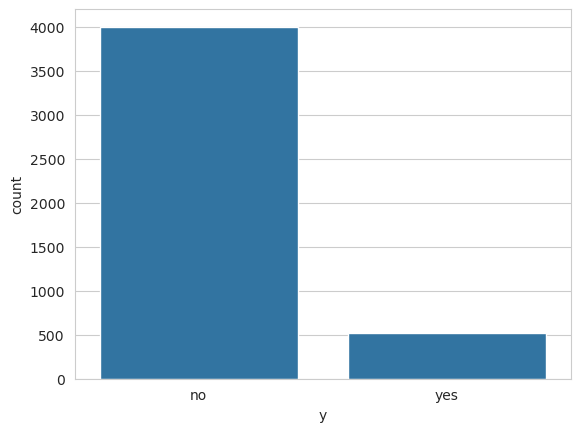

In [5]:
sns.set_style('whitegrid')
sns.countplot(df, x = 'y')

Как можно заметить, датасет не идеальный для обучения, поскольку количество значений целевого показателя сильно отличается, а именно:

In [6]:
print('Ответов "yes" всего ', round(521/4520*100, 2), '%')
print('Соотношение между ответами: 1 к ', round(3999/521, 2))

Ответов "yes" всего  11.53 %
Соотношение между ответами: 1 к  7.68


И это большое соотношение, что может нехорошо сказаться на дальнейших прогнозах. Тем не менее, данная задача подходит под тип "бинарная классификация", поскольку присутствуют 4 бинарных признаков (default, housing, loan, y).
### 2.2 Проверяем наличие пропущенных значений и выбросов

In [7]:
print(df.isnull().sum())

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


Пропущенные значения отсутствуют, прекрасно! Хотя, если присмотреться внимательнее, то можно вспомнить, что для части категориальных признаков существуют значения unknown. Далее проверим на выбросы по признакам возраста и среднегодового баланса:

<Axes: xlabel='age'>

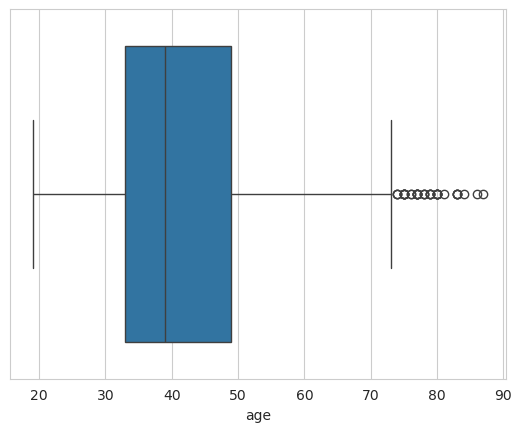

In [8]:
sns.boxplot(x=df['age'])

<Axes: xlabel='balance'>

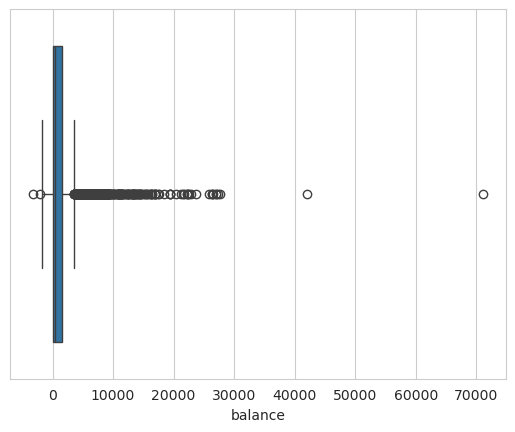

In [9]:
sns.boxplot(x=df['balance'])

In [10]:
print(min(df['balance']))

-3313


Подведём итоги анализа на выборсы: возраст сбалансирован, выбросов немного (порог верхний в 74 года, значения выше этого уже относятся к малочисленным). А вот с балансом ситуация оказалась интереснее: "ящик с усами" показал 2 серьёзных выбраса с большим балансом, но также показал, что существуют и отрицательные балансы (что было неочевидно, поскольку при выводе первых 5 строк таких случаев не было). По итогу этого было решено также узнать самый минимальный баланс (-3313). Из интересного, можно заметить, что самая частая группа, заправшивающая кредит имеет среднегодовой баланс в 0.
## 3. Преобразования
### 3.1 Исключим малозначимые признаки
К таким относятся день и месяц последнего контакта (без текущей даты датасета данные признаки бесполезны)

In [11]:
df.drop(['day', 'month'], axis = 1, inplace = True)

### 3.2 Преобразуем категориальные признаки
Признак contact можно преобразовать в isContact, где 1 будет означать присутствие, а 0 отсутствие. Также можно преобразовать результат предыдущей компании, обозначив успех за 1 и остальные варианты за 0.

In [12]:
# поскольку преобразований много, введём контроль значений
(unique, counts) = np.unique(df['contact'], return_counts = True)
print('Уникальные значения contact: ', unique)
print('Количество этих значений: ', counts)
(unique, counts) = np.unique(df['poutcome'], return_counts = True)
print('Уникальные значения poutcome: ', unique)
print('Количество этих значений: ', counts)

df['isContact'] = np.where(df['contact']=='unknown', 0, 1)
df['poutcomeBin'] = np.where(df['poutcome']=='success', 1, 0)
df.drop(['contact', 'poutcome'], axis=1, inplace = True)
df.head()

Уникальные значения contact:  ['cellular' 'telephone' 'unknown']
Количество этих значений:  [2895  301 1324]
Уникальные значения poutcome:  ['failure' 'other' 'success' 'unknown']
Количество этих значений:  [ 490  196  129 3705]


,age,job,marital,education,default,balance,housing,loan,duration,campaign,pdays,previous,y,isContact,poutcomeBin
0,30,unemployed,married,primary,no,1787,no,no,79,1,-1,0,no,1,0
1,33,services,married,secondary,no,4789,yes,yes,220,1,339,4,no,1,0
2,35,management,single,tertiary,no,1350,yes,no,185,1,330,1,no,1,0
3,30,management,married,tertiary,no,1476,yes,yes,199,4,-1,0,no,0,0
4,59,blue-collar,married,secondary,no,0,yes,no,226,1,-1,0,no,0,0


In [13]:
(unique, counts) = np.unique(df['isContact'], return_counts = True)
print('Уникальные значения isContact: ', unique)
print('Количество этих значений: ', counts)
(unique, counts) = np.unique(df['poutcomeBin'], return_counts = True)
print('Уникальные значения poutcomeBin: ', unique)
print('Количество этих значений: ', counts)

Уникальные значения isContact:  [0 1]
Количество этих значений:  [1324 3196]
Уникальные значения poutcomeBin:  [0 1]
Количество этих значений:  [4391  129]


Проверим: у нас отсутствовал контакт с 1324 клиентами в категориальном обозначении и была успешная компания с 129 клиентами. В новом бинарном представлении мы отметили отсутствие у 1324 клиентов и успех прошлой компании у 129 клиентов. Конвертация прошла успешно! Также для большего удобства преобразуем столбцы с категориями yes/no в бинарное представление 1/0. Тут обойдёмся более сложным механизмом контроля утечки, преимущество которого будет заключаться в мгновенном результате конвертации True/False.

In [14]:
df['defaultBin'] = np.where(df['default']=='no', 0, 1)
df['housingBin'] = np.where(df['housing']=='no', 0, 1)
df['loanBin'] = np.where(df['loan']=='no', 0, 1)
df['yBin'] = np.where(df['y']=='no', 0, 1)

check = ((df['default'] == 'no').sum() == (df['defaultBin'] == 0).sum() and 
         (df['housing'] == 'no').sum() == (df['housingBin'] == 0).sum() and 
         (df['loan'] == 'no').sum() == (df['loanBin'] == 0).sum() and 
         (df['y'] == 'no').sum() == (df['yBin'] == 0).sum())
print ('Результат конвертации: ', check)
if (check):
    df.drop(['default', 'housing', 'loan', 'y'], axis=1, inplace = True)
df.head()

Результат конвертации:  True


,age,job,marital,education,balance,duration,campaign,pdays,previous,isContact,poutcomeBin,defaultBin,housingBin,loanBin,yBin
0,30,unemployed,married,primary,1787,79,1,-1,0,1,0,0,0,0,0
1,33,services,married,secondary,4789,220,1,339,4,1,0,0,1,1,0
2,35,management,single,tertiary,1350,185,1,330,1,1,0,0,1,0,0
3,30,management,married,tertiary,1476,199,4,-1,0,0,0,0,1,1,0
4,59,blue-collar,married,secondary,0,226,1,-1,0,0,0,0,1,0,0


In [15]:
# после успешной конвертации переименуем колонки, откинув приписку Bin
# не записал сразу в ту же колонку с целью проверки конвертации на утечку значений
df = df.rename(columns={'poutcomeBin' : 'poutcome', 'defaultBin' : 'default',
                        'housingBin' : 'housing', 'loanBin' : 'loan', 'yBin' : 'y'})
df.head()

,age,job,marital,education,balance,duration,campaign,pdays,previous,isContact,poutcome,default,housing,loan,y
0,30,unemployed,married,primary,1787,79,1,-1,0,1,0,0,0,0,0
1,33,services,married,secondary,4789,220,1,339,4,1,0,0,1,1,0
2,35,management,single,tertiary,1350,185,1,330,1,1,0,0,1,0,0
3,30,management,married,tertiary,1476,199,4,-1,0,0,0,0,1,1,0
4,59,blue-collar,married,secondary,0,226,1,-1,0,0,0,0,1,0,0


### 3.3 Кодируем категоривальные признаки
Признаки job, marital и education закодируем при помощи OneHotEncoder:

In [16]:
# импортируем и создаём энкодер
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# обучаем на всех данных
encoded_array = encoder.fit_transform(df[['job']])
df_enc1 = pd.DataFrame(encoded_array, columns = encoder.get_feature_names_out(['job']))

# сразу приводим к типу int64
df_enc1 = df_enc1.astype('int64')
df_enc1.head()

,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown
0,0,0,0,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,0,0
3,0,0,0,0,1,0,0,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0


In [17]:
encoded_array = encoder.fit_transform(df[['marital']])
df_enc2 = pd.DataFrame(encoded_array, columns = encoder.get_feature_names_out(['marital']))
df_enc2 = df_enc2.astype('int64')
df_enc2.head()

,marital_divorced,marital_married,marital_single
0,0,1,0
1,0,1,0
2,0,0,1
3,0,1,0
4,0,1,0


In [18]:
encoded_array = encoder.fit_transform(df[['education']])
df_enc3 = pd.DataFrame(encoded_array, columns = encoder.get_feature_names_out(['education']))
df_enc3 = df_enc3.astype('int64')
df_enc3.head()

,education_primary,education_secondary,education_tertiary,education_unknown
0,1,0,0,0
1,0,1,0,0
2,0,0,1,0
3,0,0,1,0
4,0,1,0,0


In [19]:
df = df.join(df_enc1)
df = df.join(df_enc2)
df = df.join(df_enc3)
df.drop(['job', 'marital', 'education', 'job_unknown', 'marital_single', 'education_unknown'], axis=1, inplace=True)
df.head()

,age,balance,duration,campaign,pdays,previous,isContact,poutcome,default,housing,...,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,education_primary,education_secondary,education_tertiary
0,30,1787,79,1,-1,0,1,0,0,0,...,0,0,0,0,1,0,1,1,0,0
1,33,4789,220,1,339,4,1,0,0,1,...,0,1,0,0,0,0,1,0,1,0
2,35,1350,185,1,330,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,1
3,30,1476,199,4,-1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
4,59,0,226,1,-1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0


## 4. Машинное обучение
### 4.1 Разделяем данные на признаки и целевую переменную

In [20]:
y = df['y']
X = df.drop('y', axis=1)
X

,age,balance,duration,campaign,pdays,previous,isContact,poutcome,default,housing,...,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,education_primary,education_secondary,education_tertiary
0,30,1787,79,1,-1,0,1,0,0,0,...,0,0,0,0,1,0,1,1,0,0
1,33,4789,220,1,339,4,1,0,0,1,...,0,1,0,0,0,0,1,0,1,0
2,35,1350,185,1,330,1,1,0,0,1,...,0,0,0,0,0,0,0,0,0,1
3,30,1476,199,4,-1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
4,59,0,226,1,-1,0,0,0,0,1,...,0,0,0,0,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4515,32,473,624,5,-1,0,1,0,0,1,...,0,1,0,0,0,0,0,0,1,0
4516,33,-333,329,5,-1,0,1,0,0,1,...,0,1,0,0,0,0,1,0,1,0
4517,57,-3313,153,1,-1,0,0,0,1,1,...,1,0,0,0,0,0,1,0,0,1
4518,57,295,151,11,-1,0,1,0,0,0,...,0,0,0,1,0,0,1,0,1,0


### 4.2 Разделяем данные на тренировочный и тестовый наборы
75% используем для обучения и 25% для тестирования

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)

### 4.3 Применяем операцию нормализации для численной устойчивости

In [22]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 4.4 Обучаем модель логистической регрессии

In [23]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 4.5 Делаем прогноз на основе данных тестирования

In [24]:
y_pred = model.predict(X_test_scaled)

## 5. Анализ результатов обучения
### 5.1 Рассчитываем показатели точности

In [25]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = confusion_matrix(y_test, y_pred).ravel()
print('True Positive = ', TP)
print('False Positive = ', FP)
print('TrueNegative = ', TN)
print('FalseNegative = ', FN)
accuracy = (TP + TN) / (TP + FP + TN + FN)
print('Accuracy of the binary classification = ', accuracy.round(3))

True Positive =  42
False Positive =  24
TrueNegative =  965
FalseNegative =  99
Accuracy of the binary classification =  0.891


Крайне хороший показатель правильных ответов! Оценим точность модели иным способом:

In [26]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print('Accuracy: ', accuracy)

Accuracy:  0.8911504424778761


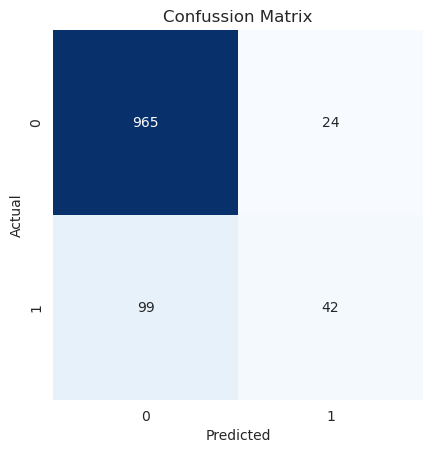

In [27]:
# построим карту ответов
sns.heatmap(cm, square = True, annot = True, fmt = 'd', cbar = False, cmap = 'Blues')
plt.title('Confussion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Можно заметить, что модель лучше всего определяет отказы, но из-за плохого соотношения отказов к согласиям (в изначальном датасете) модель также часто делает отказы в тех местах, где следовало бы согласиться. С ошибочными соглашениями ситуация обстоит лучше. В целом же, можно оценить пропорциональность ошибочного в каждом отдельном случае:

In [28]:
print('Ошибочность при отказах: ', FN/(FN+TN))
print('Ошибочность при согласиях: ', FP/(FP+TP))

Ошибочность при отказах:  0.09304511278195489
Ошибочность при согласиях:  0.36363636363636365


Теория подтвердилась, модель хорошо умеет работать с отказами и делает всё верно в 90% случаев. А вот с согласиями у модели хуже - верно она соглашается лишь в 63%, делая при этом ошибки в 36% (не очень хороший показатель, хотя лучше базового в 50%).

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print('Точность: ', round(precision, 2))
print('Полнота: ', round(recall, 2))
print('F1-мера: ', round(f1, 2))

Точность:  0.64
Полнота:  0.3
F1-мера:  0.41


А вот тут всё пошло печально, это видно по F1-мере. В свою очередь на неё так повлияла низкая полнота (полагаю, это из-за ошибочности в согласиях). Построим матрицу корреляции:

In [30]:
df.corr()

,age,balance,duration,campaign,pdays,previous,isContact,poutcome,default,housing,...,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,education_primary,education_secondary,education_tertiary
age,1.000000,0.083827,-0.002385,-0.005133,-0.009022,-0.003743,0.035089,0.048637,-0.017877,-0.193957,...,0.005518,-0.078334,-0.186685,-0.072698,-0.004249,0.148068,0.275266,0.224969,-0.106825,-0.094158
balance,0.083827,1.000000,-0.015944,-0.009982,0.009485,0.026319,0.018906,0.029995,-0.070889,-0.050213,...,-0.002069,-0.033766,0.005537,-0.013789,-0.018906,-0.036292,0.017134,-0.001560,-0.076605,0.076540
duration,-0.002385,-0.015944,1.000000,-0.068366,0.010241,0.017846,0.005425,0.049267,-0.011606,0.015682,...,0.000144,-0.001787,-0.008077,-0.020484,0.024520,0.021399,-0.036355,-0.003611,0.023252,-0.017889
campaign,-0.005133,-0.009982,-0.068366,1.000000,-0.093064,-0.067727,-0.004846,-0.058279,-0.012355,-0.003524,...,0.032029,0.002946,-0.017742,-0.009025,-0.006265,-0.022178,0.021932,0.009723,-0.019570,0.022724
pdays,-0.009022,0.009485,0.010241,-0.093064,1.000000,0.577006,0.246103,0.212370,-0.026269,0.116555,...,-0.023531,-0.010668,0.008242,-0.002056,-0.005280,-0.003244,-0.015958,-0.019524,0.012378,-0.000332
previous,-0.003743,0.026319,0.017846,-0.067727,0.577006,1.000000,0.193920,0.250826,-0.026589,0.037946,...,0.005954,-0.018384,0.034437,0.009545,-0.005732,-0.021887,-0.016595,-0.020118,-0.007563,0.025732
isContact,0.035089,0.018906,0.005425,-0.004846,0.246103,0.193920,1.000000,0.104481,-0.014133,-0.215497,...,-0.020707,-0.051827,0.041775,0.038785,0.013169,-0.027754,-0.037737,-0.083592,-0.042327,0.130834
poutcome,0.048637,0.029995,0.049267,-0.058279,0.212370,0.250826,0.104481,1.000000,-0.022415,-0.088479,...,-0.014984,-0.013320,0.015768,0.021516,0.002779,-0.020969,0.005948,-0.016187,-0.015450,0.015970
default,-0.017877,-0.070889,-0.011606,-0.012355,-0.026269,-0.026589,-0.014133,-0.022415,1.000000,0.006907,...,0.008058,-0.000068,-0.005254,0.009561,0.008794,0.048868,-0.039075,-0.006747,0.024875,-0.021368
housing,-0.193957,-0.050213,0.015682,-0.003524,0.116555,0.037946,-0.215497,-0.088479,0.006907,1.000000,...,-0.035251,0.075593,-0.091020,-0.012639,-0.038854,-0.001127,0.038689,-0.000875,0.111588,-0.098955


Можно заметить, что боьше всего на результат влияет продолжительность последнего контакта и результат последней маркетинговой компании (0.4 и 0.28 соответственно).
## 5.2 Строим ROC-кривую

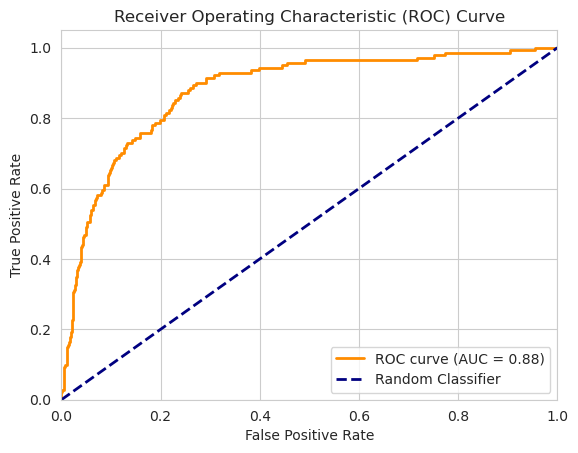

In [31]:
from sklearn.metrics import roc_curve, auc

# получаем предсказание вероятности для класса 1
y_score = model.predict_proba(X_test_scaled)[:, 1]

# рассчитываем FPR, TPR и пороги
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# рассчитываем Area Under Curve (AUC)
roc_auc = auc(fpr, tpr)

# строим график
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

РОГ кривая содержит под собой площадь в 0.88, что является очень хорошим показателем.
### 5.3 Подготовка данных для прогноза

In [32]:
# у нас есть row_for_test, которую мы извлекли в начале. Проверим на ней итог программы
# для начала получим список всех текущих колонок
df.columns

Index(['age', 'balance', 'duration', 'campaign', 'pdays', 'previous',
       'isContact', 'poutcome', 'default', 'housing', 'loan', 'y',
       'job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid',
       'job_management', 'job_retired', 'job_self-employed', 'job_services',
       'job_student', 'job_technician', 'job_unemployed', 'marital_divorced',
       'marital_married', 'education_primary', 'education_secondary',
       'education_tertiary'],
      dtype='object')

In [33]:
test_data = pd.DataFrame({'age':[44], 'balance':[1136], 'duration':[345], 'campaign':[2], 'pdays':[249],
                          'previous':[7], 'isContact':[1], 'poutcome':[0], 'default':[0], 'housing':[1],
                          'loan':[1], 'job_admin.':[0], 'job_blue-collar':[0], 'job_entrepreneur':[1],
                          'job_housemaid':[0], 'job_management':[0], 'job_retired':[0], 'job_self-employed':[0],
                          'job_services':[0], 'job_student':[0], 'job_technician':[0], 'job_unemployed':[0],
                          'marital_divorced':[0], 'marital_married':[0], 'education_primary':[0],
                          'education_secondary':[0], 'education_tertiary':[1]})
new_data_scaled = scaler.transform(test_data)

# предсказываем ответ (0 или 1)
predicted_answer = model.predict(new_data_scaled)
print('Предсказанный ответ: ', predicted_answer)
print('Совпадение: ', (predicted_answer==0))

Предсказанный ответ:  [0]
Совпадение:  [ True]


In [34]:
# предсказываем вероятность
predicted_proba = model.predict_proba(new_data_scaled)
print('Вероятности для классов [0, 1]: ', predicted_proba)
print('Вероятность согласия на кредит: ', round(predicted_proba[0][1]*100, 2), '%')

Вероятности для классов [0, 1]:  [[0.94511257 0.05488743]]
Вероятность согласия на кредит:  5.49 %


Модель прошла тест успешно!
## 6. Исследовательский анализ данных (EDA)

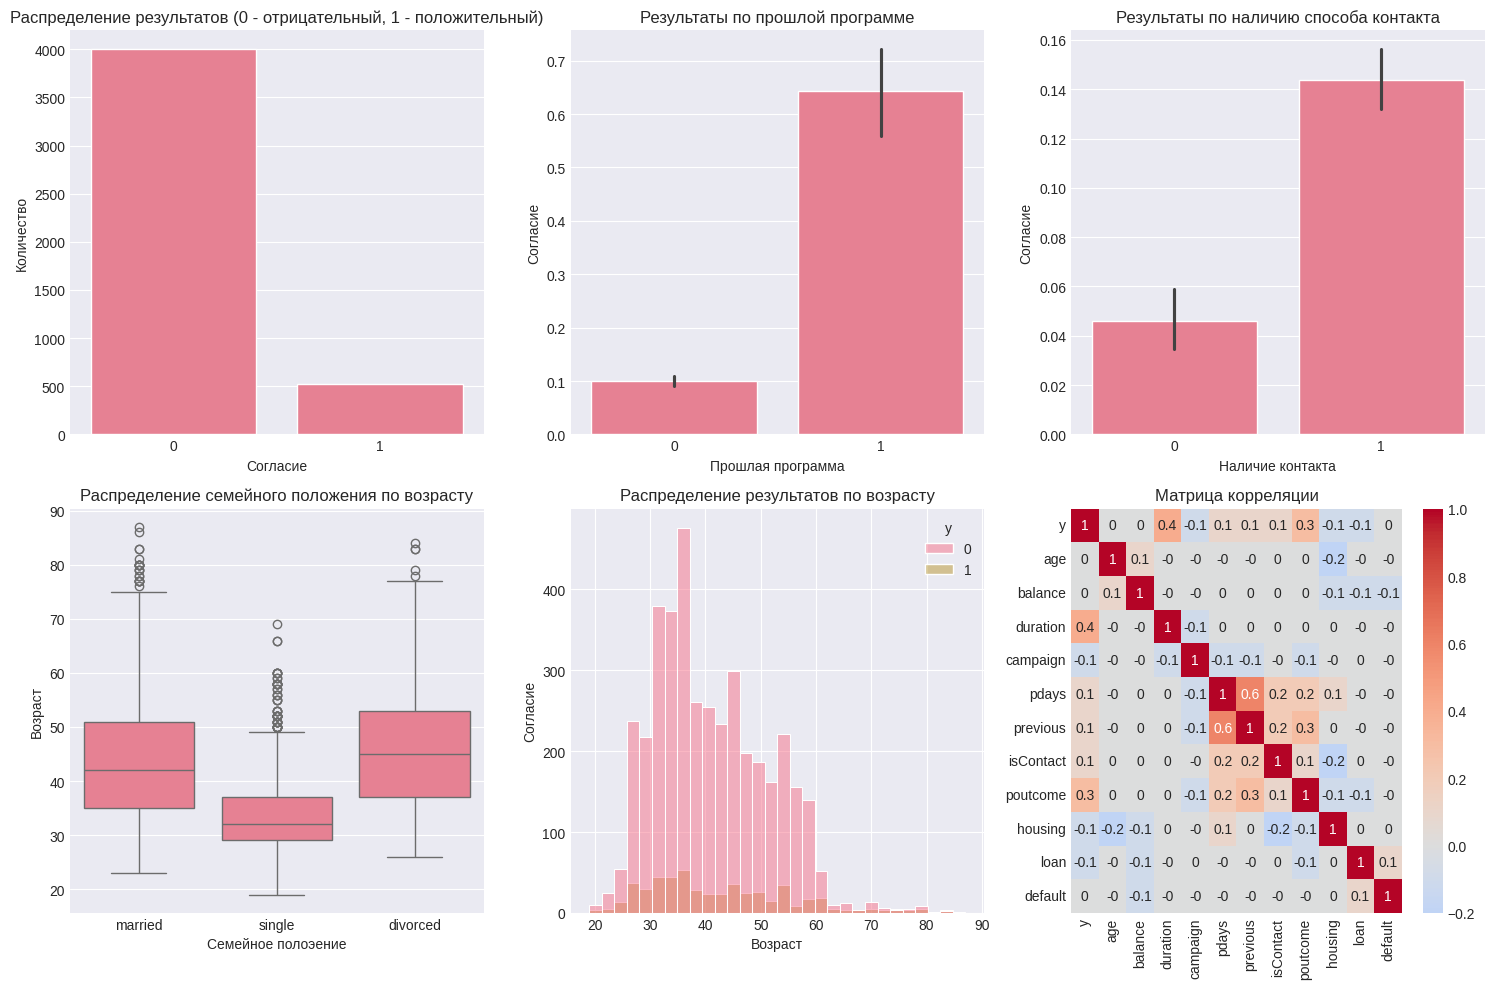

In [40]:
# настройка визуализации
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# целевая переменная
sns.countplot(data=df, x='y', ax = axes[0, 0])
axes[0, 0].set_title('Распределение результатов (0 - отрицательный, 1 - положительный)')
axes[0, 0].set_xlabel('Согласие')
axes[0, 0].set_ylabel('Количество')

sns.barplot(data=df, x='poutcome', y='y', ax = axes[0, 1])
axes[0, 1].set_title('Результаты по прошлой программе')
axes[0, 1].set_xlabel('Прошлая программа')
axes[0, 1].set_ylabel('Согласие')

sns.barplot(data=df, x='isContact', y='y', ax = axes[0, 2])
axes[0, 2].set_title('Результаты по наличию способа контакта')
axes[0, 2].set_xlabel('Наличие контакта')
axes[0, 2].set_ylabel('Согласие')

sns.boxplot(data=df_copy, x='marital', y='age', ax=axes[1,0])
axes[1, 0].set_title('Распределение семейного положения по возрасту')
axes[1, 0].set_xlabel('Семейное полоэение')
axes[1, 0].set_ylabel('Возраст')

sns.histplot(data=df, x='age', hue='y', bins=30, ax=axes[1,1])
axes[1, 1].set_title('Распределение результатов по возрасту')
axes[1, 1].set_xlabel('Возраст')
axes[1, 1].set_ylabel('Согласие')

corr_matrix = df[['y', 'age', 'balance', 'duration',	'campaign', 'pdays', 'previous', 
    'isContact', 'poutcome', 'housing', 'loan', 'default']].corr().round(1)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=axes[1,2])
axes[1, 2].set_title('Матрица корреляции')

plt.tight_layout()
plt.show()

Из интересных наблюдений по графикам результата - исходя из матрицы корреляций, мы видим, что возраст и баланс слабо влияют на итог. А вот данные по контакту (когда, сколько, какой итог) влияют очень.

Лабораторная работа выполнена. 